# Top-10 рекомендации для Amazon Video Games: пять моделей с нуля

**Мозжухин Александр Васильевич** · ДЗ 1 по рекомендательным системам

**Задача.** По истории отзывов порекомендовать 10 ещё не оценённых товаров, которым пользователь
в будущем поставит 4–5. Основная метрика — NDCG@10 (выбрана до подбора). Дополнительные —
Recall@10, HitRate@10 и Coverage@10.

**Данные.** Amazon Reviews 2014, категория Video Games. Настройки подбираются на 2013 годе.
Финальное обучение — на отзывах до 2014 года, test — январь–июль 2014: 3254 пользователя,
каталог 3998 товаров.

## Главное

| Модель (test) | NDCG@10 | Recall@10 | Coverage@10 |
|---|---:|---:|---:|
| Fusion: 0.7·FM + 0.3·CustomALS | **0.0753** | **0.1217** | 0.316 |
| Popularity за 30 дней | 0.0680 | 0.1044 | 0.006 |
| FM: пользователь, товар, возраст товара | 0.0609 | 0.1014 | 0.273 |
| CustomALS: оценка и давность отзыва | 0.0572 | 0.0944 | 0.361 |
| iALS | 0.0563 | 0.0914 | 0.144 |
| EASE | 0.0530 | 0.0885 | 0.563 |
| ItemKNN | 0.0477 | 0.0823 | 0.612 |
| Popularity за всё время | 0.0460 | 0.0763 | 0.005 |

- **Время — главный сигнал.** Популярность за последние 30 дней точнее каждой из пяти моделей:
  лучшая из них, FM, ниже на 0.007 (95% CI [−0.014, 0.000]).
- **Метаданные помогают FM**, если брать их на момент события. Возраст товара даёт +0.019 NDCG@10
  к FM только с ID, CI [0.013, 0.025].
- **Затухание по давности в CustomALS** даёт +0.011 к той же модели без времени, CI [0.008, 0.014].
  Отдельно подобранный iALS отстаёт от CustomALS лишь на 0.001, и интервал включает ноль.
- **Fusion FM и CustomALS** даёт лучший результат: +0.014 к FM, CI [0.009, 0.019].

## Запуск

```bash
python3 -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt
jupyter execute experiments.ipynb --inplace --timeout=-1
```

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pipeline.data import DAY, download, make_phase, read_clean
from pipeline.evaluation import EvaluationSet
from pipeline.experiment import MAIN_MODELS, describe, grid, run_test, run_validation

ROOT = Path.cwd()
RESULTS, FIGURES = ROOT / "results", ROOT / "results/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.options.display.float_format = "{:.4f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

CONFIG = {
    "seed": 42, "repeat_seeds": [43, 44], "k": 10, "primary_metric": "ndcg@10",
    "threads": 1, "workers": 4, "bootstrap_repeats": 2000,
    "data": {"catalog_size": 4000, "min_reviews": 3},
    "search": {
        "Popularity": {"window_days": [7, 14, 30, 90, 180, 365, None]},
        "ItemKNN": {"k": [25, 75, 150, 300], "shrinkage": [0, 10, 20, 50], "signal": ["positive", "observed"]},
        "EASE": {"l2": [10, 30, 100, 300, 1000], "signal": ["positive", "observed"]},
        "IALS": {"n_factors": [32, 64, 128], "alpha": [10, 40, 160, 640], "l2": [30, 100, 300, 1000, 3000],
                 "n_iters": [20]},
        "FM": {"factors": [64, 128, 256], "item_features": ["age", "all"], "epochs": [10, 25, 50],
               "weight_decay": [1e-6], "learning_rate": [0.01], "negative_ratio": [3],
               "batch_size": [4096], "num_threads": [4]},
        "CustomALS": {"n_factors": [64, 128], "alpha": [10, 40, 160, 640], "l2": [30, 100, 300, 1000, 3000], "n_iters": [20],
                      "half_life_days": [90, 180, 365], "recency_mix": [0.5]},
    },
    "fusion_weights": [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
}


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Данные

[Amazon Reviews 2014](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon/links.html) (McAuley, UCSD),
категория Video Games, полный ratings-only файл
([CSV](https://mcauleylab.ucsd.edu/public_datasets/data/amazon/categoryFiles/ratings_Video_Games.csv)).

| Поле | Смысл |
|---|---|
| `user_id` | автор отзыва |
| `item_id` | ASIN товара: игры, консоли, аксессуары |
| `rating` | оценка 1–5 |
| `timestamp` | дата отзыва (с точностью до дня) |

**Взаимодействие** — отзыв. **Релевантный товар** — товар, который пользователь в будущем оценит на 4–5.
Товары с оценкой 1–3 тоже известны системе: их не рекомендуем повторно, а iALS, CustomALS и FM
используют их как наблюдаемые негативы. Метаданные товара строятся по времени отзывов (раздел 2).

In [2]:
clean, source = read_clean(download(ROOT / ".cache/raw/ratings_Video_Games.csv"))
phases = {"validation": make_phase(clean, "validation", "2013-01-01", "2014-01-01", **CONFIG["data"]),
          "test": make_phase(clean, "test", "2014-01-01", **CONFIG["data"])}
sizes = pd.DataFrame(
    [{"": "исходный файл", "отзывы": source["rows"], "пользователи": source["users"], "товары": source["items"]}]
    + [{"": f"{name}: история + holdout", "отзывы": len(p.history) + len(p.holdout),
        "пользователи": p.n_users, "товары": p.n_items} for name, p in phases.items()]).set_index("")
print(f"Пропуски: {source['missing_values']}, некорректные строки: {source['invalid_rows']}, "
      f"повторные пары user–item: {source['duplicate_rows']}")
sizes

Пропуски: 0, некорректные строки: 0, повторные пары user–item: 0


,отзывы,пользователи,товары
,,,
исходный файл,1324753,826767,50210
validation: история + holdout,155137,27007,3997
test: история + holdout,217008,40204,3998


## 2. EDA и отбор

Пропусков, некорректных значений и повторных пар нет. При повторе оставлялся бы самый ранний отзыв.

**Отбор** выполняется для каждой фазы отдельно и только по отзывам до её среза:
- каталог — 4000 товаров с наибольшим числом отзывов. Ограничение нужно для EASE (плотная матрица 4000×4000)
  и полного перебора кандидатов;
- пользователи — не менее 3 отзывов о товарах каталога. Для пользователей с одним отзывом персонализация
  почти невозможна, а у validation-фазы без порога было бы около 200 тысяч таких пользователей.

Обе фазы укладываются в требования задания: 155 и 217 тысяч отзывов, больше 1000 пользователей и товаров.

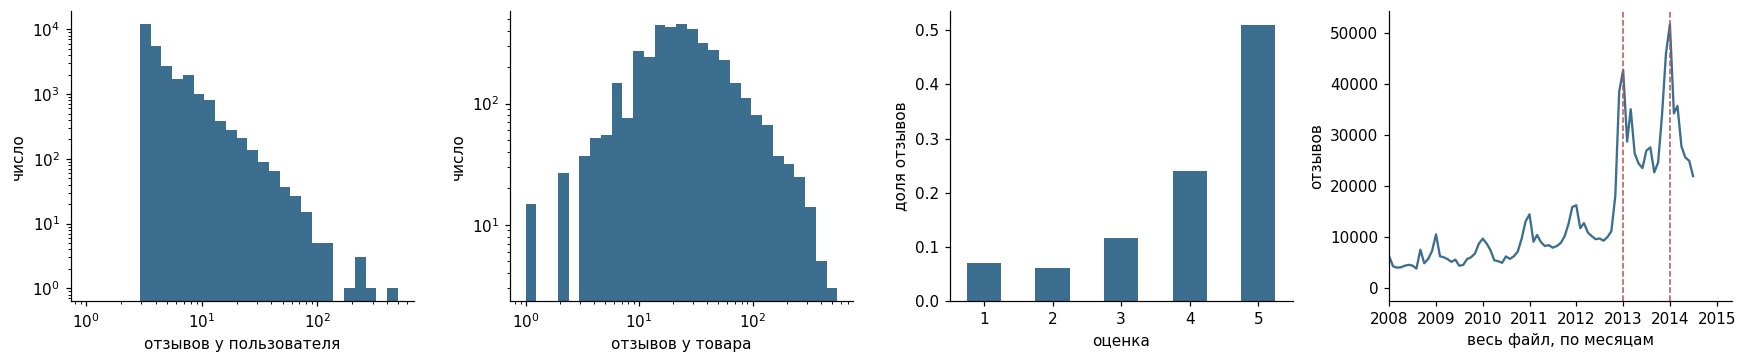

validation-фаза: медиана 4 отзыва на пользователя, 24 на товар; заполненность матрицы 0.14%; оценки 4–5 — 75%


In [3]:
history = phases["validation"].history
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
for axis, counts, label in ((ax[0], history.groupby("user").size(), "отзывов у пользователя"),
                            (ax[1], history.groupby("item").size(), "отзывов у товара")):
    axis.hist(counts, bins=np.geomspace(1, counts.max() + 1, 30), color="#3b6e8f")
    axis.set(xscale="log", yscale="log", xlabel=label, ylabel="число")
history.rating.astype(int).value_counts(normalize=True).sort_index().plot.bar(ax=ax[2], color="#3b6e8f", rot=0)
ax[2].set(xlabel="оценка", ylabel="доля отзывов")
monthly = clean.groupby(pd.to_datetime(clean.timestamp, unit="s").dt.to_period("M")).size()
ax[3].plot(monthly.index.to_timestamp(), monthly.values, color="#3b6e8f")
for cutoff in ("2013-01-01", "2014-01-01"):
    ax[3].axvline(pd.Timestamp(cutoff), color="#c0504d", ls="--", lw=1)
ax[3].set(xlabel="весь файл, по месяцам", ylabel="отзывов", xlim=(pd.Timestamp("2008-01-01"), None))
save(fig, "01_eda")
p = phases["validation"]
print(f"validation-фаза: медиана {history.groupby('user').size().median():.0f} отзыва на пользователя, "
      f"{history.groupby('item').size().median():.0f} на товар; заполненность матрицы "
      f"{len(history) / (p.n_users * p.n_items):.2%}; оценки 4–5 — {(history.rating >= 4).mean():.0%}")

Распределения активности и популярности — с тяжёлым хвостом. Матрица заполнена на 0.14%,
75% отзывов положительные. Число отзывов быстро растёт: за 2013 год их вдвое больше, чем за 2012-й.

**Метаданные: время.** В файле нет жанров и описаний. Товар описывают его отзывы до среза: возраст (дни
с первого отзыва), сколько у него отзывов всего и за последнее время. График ниже показывает, что
время — сильный сигнал.

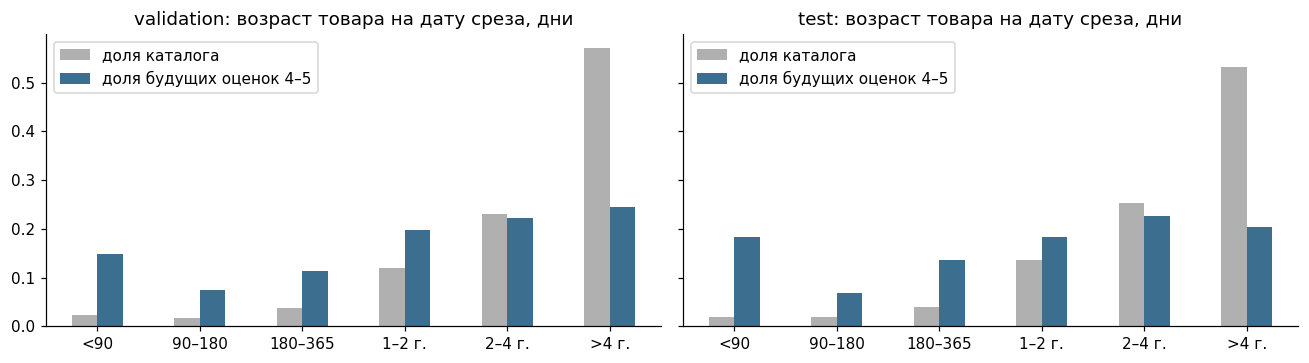

,validation,test
популярность товара,,
за 90 дней,0.5551,0.5714
за 180 дней,0.5783,0.6063
за всё время,0.3563,0.4362


In [4]:
bins, labels = [0, 90, 180, 365, 730, 1460, np.inf], ["<90", "90–180", "180–365", "1–2 г.", "2–4 г.", ">4 г."]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
correlations = {}
for axis, (name, p) in zip(ax, phases.items()):
    first = p.history.groupby("item").timestamp.min().reindex(range(p.n_items)).to_numpy()
    age = pd.cut((p.cutoff - first) / DAY, bins, right=False, labels=labels)
    future = p.holdout[p.holdout.rating >= 4].item.to_numpy()
    shares = pd.DataFrame({"доля каталога": pd.Series(age).value_counts(normalize=True),
                           "доля будущих оценок 4–5": pd.Series(age[future]).value_counts(normalize=True)})
    shares.loc[labels].plot.bar(ax=axis, rot=0, color=["#b0b0b0", "#3b6e8f"])
    axis.set(title=f"{name}: возраст товара на дату среза, дни", xlabel="")
    future_count = pd.Series(np.bincount(future, minlength=p.n_items))
    correlations[name] = {f"за {w} дней" if w else "за всё время":
                          pd.Series(p.popularity(w)).corr(future_count, method="spearman") for w in (90, 180, None)}
save(fig, "02_item_age")
pd.DataFrame(correlations).rename_axis("популярность товара")  # Спирмен с числом будущих оценок 4–5

Товары моложе 90 дней — около 2% каталога, но получают 15–18% будущих положительных отзывов.
Популярность за последние 180 дней предсказывает будущие оценки 4–5 заметно лучше накопленной.
Из этого следуют три решения: baseline по недавней популярности, затухание по давности в CustomALS
и признаки товара на момент события в FM.

## 3. Протокол оценки

| Фаза | Обучение (история) | Holdout | Назначение |
|---|---|---|---|
| validation | до 2013-01-01 | 2013 год | подбор всех настроек |
| test | до 2014-01-01 | 2014-01-01 — 2014-07-23 | однократная финальная оценка |

- **Пользователи оценки** — из осей фазы, у которых в holdout есть хотя бы одна новая оценка 4–5.
  Список один для всех моделей.
- **Кандидаты** — весь каталог фазы минус все товары из истории пользователя, с любой оценкой.
  Negative sampling при оценке нет.
- **Новые пользователи и товары** (вне осей фазы) не оцениваются: работа о warm-start. Их отзывы
  составляют подавляющую часть holdout (таблица ниже), поэтому выводы относятся только к активным
  пользователям и популярному каталогу.
- **Равные scores** упорядочиваются по числу положительных отзывов в истории, затем по ID.
- Выбранные на validation настройки переносятся в test-фазу. Модели переобучаются на её истории.


Для пользователя $u$ с релевантными товарами $R_u$ и списком $L_u$:
$$\mathrm{NDCG@10}(u)=\frac{\sum_{j=1}^{10}1[L_{uj}\in R_u]/\log_2(j+1)}{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)},\qquad
\mathrm{Recall@10}(u)=\frac{|L_u\cap R_u|}{|R_u|}.$$
NDCG — основная метрика: важна позиция попадания в коротком списке. Recall — доля найденных будущих
положительных оценок. HitRate@10 — доля пользователей хотя бы с одним попаданием. Coverage@10 — доля
каталога, попавшая хотя бы в один список: показывает, не сводится ли модель к популярным товарам.
Средние берутся по пользователям.

In [5]:
cohorts = {}
for name, p in phases.items():
    ev = EvaluationSet.from_phase(p, CONFIG["k"]).report()
    cohorts[name] = {"holdout в осях": len(p.holdout), "holdout вне осей": p.dropped_holdout_rows,
                     "пользователи оценки": ev["users"], "релевантные пары": ev["relevant_pairs"],
                     "кандидатов на пользователя": round(ev["candidates_mean"])}
pd.DataFrame(cohorts).T

,holdout в осях,holdout вне осей,пользователи оценки,релевантные пары,кандидатов на пользователя
validation,6851,356009,2569,5254,3989
test,7822,214187,3254,6008,3990


## 4. Модели

$O_{ui}=1$, если есть отзыв; $X_{ui}=1[r_{ui}\ge4]$. Обучение, предсказание и ранжирование реализованы
на NumPy/SciPy/PyTorch, без готовых рекомендательных моделей.

**ItemKNN** — [`models/item_knn.py`](models/item_knn.py). Косинус со shrinkage
$s_{ij}=\frac{n_{ij}}{\sqrt{n_{ii}n_{jj}}}\cdot\frac{n_{ij}}{n_{ij}+\gamma}$, $n_{ij}=X_{\cdot i}^\top X_{\cdot j}$.
У каждого товара остаётся $k$ соседей, score — $x_u^\top S$.

**iALS** — [`models/ials.py`](models/ials.py), Hu et al. (2008).
$\min\sum_{u,i}c_{ui}(p_{ui}-a_u^\top b_i)^2+\lambda(\|A\|_F^2+\|B\|_F^2)$, где $p_{ui}=X_{ui}$ и $c_{ui}=1+\alpha O_{ui}$.
Низкая оценка — уверенный ноль, неизвестная пара — слабый ноль. Шаг по пользователю:
$(B^\top B+\alpha B_{O_u}^\top B_{O_u}+\lambda I)\,a_u=(1+\alpha)B^\top p_u$, по товарам — симметрично.


**EASE** — [`models/ease.py`](models/ease.py), Steck (2019).
$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2$ при $\operatorname{diag}B=0$. Решение в замкнутой форме:
$B_{ij}=-P_{ij}/P_{jj}$, где $P=(X^\top X+\lambda I)^{-1}$.


**FM** — [`models/fm.py`](models/fm.py), Rendle (2010). One-hot поля: пользователь, товар и признаки
товара на момент события; $\hat y(x)=w_0+\sum_j w_jx_j+\sum_{j<l}\langle v_j,v_l\rangle x_jx_l$.
Функция потерь — BCE, оптимизатор — Adam. В каждой эпохе используются все отзывы с меткой $1[r\ge4]$
и по 3 новых случайных неизвестных товара на каждый положительный отзыв.

Признаки товара в момент $t$ считаются только по отзывам строго до $t$: возраст (дни с первого отзыва),
число отзывов всего и за последние 90 дней. Значения разбиты на интервалы. Набор полей — гиперпараметр:
`age` или все три (`all`). Обучающий отзыв получает признаки на свою дату. Негатив получает их на дату
положительного отзыва, для которого он сэмплирован. При рекомендации признаки берутся на дату среза.


**CustomALS** — [`models/custom_als.py`](models/custom_als.py). Решатель и confidence — как у iALS,
но вместо $p_{ui}$ используется собственная цель:
$$q_{ui}=\frac{r_{ui}-3}{2}\Big[(1-\eta)+\eta\,2^{-\Delta t_{ui}/h}\Big],$$
где $\Delta t_{ui}$ — давность отзыва в днях на дату среза, $h$ — период полураспада, $\eta=0.5$.
Знак отделяет понравившееся от непонравившегося: в iALS оценки 1–3 — одинаковый ноль. Модуль различает
оценки 4 и 5. Множитель давности снижает вес старых вкусов: по EDA спрос смещается к новым товарам.
Половина веса не затухает, поэтому старая история не обнуляется.

**Ориентиры** (не входят в пять моделей): **Popularity** — число оценок 4–5 за последние $W$ дней,
$W$ подбирается; **Popularity_all_time** — за всё время. **Fusion** — $w z_1+(1-w)z_2$, где $z$ —
стандартизованные по каталогу scores двух лучших на validation моделей, $w$ подбирается.


**Контроли на test:** `FM_ID_only` — FM без признаков товара при тех же настройках, инициализации
и потоке негативов. `CustomALS_no_time` — $\eta=0$. `CustomALS_matched` — $f$, $\alpha$, $\lambda$ от iALS
и цель CustomALS. Масштаб $q$ меньше, чем у $p$, поэтому при том же $\lambda$ регуляризация сильнее.

## 5. Подбор на validation

Каждая конфигурация обучается на истории до 2013 года, и для неё считается NDCG@10 на 2013 годе.
Выбирается максимум. ALS обучается 20 итераций. FM с каждым набором настроек обучается один раз
и оценивается после 10, 25 и 50 эпох. Это эквивалентно отдельному обучению на каждое число эпох:
те же seed и поток негативов. Конфигурации считаются параллельно в 4 процессах. У каждой свой seed,
поэтому результат не зависит от числа процессов.

In [6]:
pd.DataFrame([{"модель": name, "конфигураций": len(grid(space)),
               "пространство": "; ".join(f"{k}: {v}" for k, v in space.items() if len(v) > 1)}
              for name, space in CONFIG["search"].items()]).set_index("модель")

,конфигураций,пространство
модель,,
Popularity,7,"window_days: [7, 14, 30, 90, 180, 365, None]"
ItemKNN,32,"k: [25, 75, 150, 300]; shrinkage: [0, 10, 20, ..."
EASE,10,"l2: [10, 30, 100, 300, 1000]; signal: ['positi..."
IALS,60,"n_factors: [32, 64, 128]; alpha: [10, 40, 160,..."
FM,18,"factors: [64, 128, 256]; item_features: ['age'..."
CustomALS,120,"n_factors: [64, 128]; alpha: [10, 40, 160, 640..."


In [7]:
trials, selection = run_validation(phases["validation"], CONFIG, RESULTS)
order = MAIN_MODELS + ["Popularity", "Fusion"]
pd.DataFrame([{"модель": name, "NDCG@10": selection[name]["ndcg@10"], "Recall@10": selection[name]["recall@10"],
               "настройки": describe(selection[name]["params"])} for name in order]).set_index("модель")

,NDCG@10,Recall@10,настройки
модель,,,
ItemKNN,0.0415,0.0655,"k=150, γ=10, вход=observed"
IALS,0.0425,0.0620,"f=64, α=160, λ=1000"
EASE,0.0473,0.0777,"λ=100, вход=observed"
FM,0.0494,0.0781,"f=128, признаки=age, epochs=25"
CustomALS,0.0489,0.0775,"f=128, α=160, λ=300, h=90, η=0.5"
Popularity,0.0425,0.0761,окно=30
Fusion,0.0642,0.1047,0.7·FM + 0.3·CustomALS


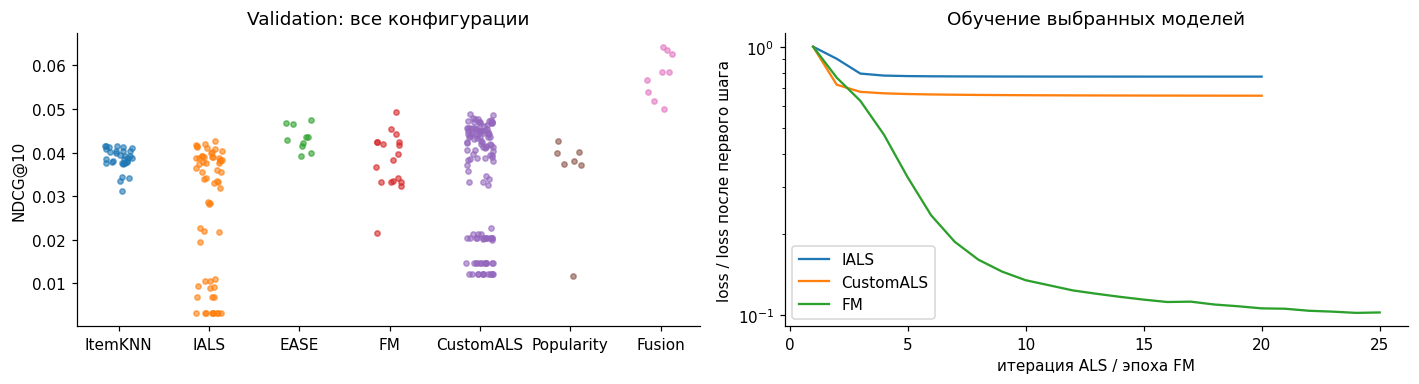

лучший NDCG@10
EASE: вход            positive          0.0435
                      observed          0.0473
ItemKNN: вход         positive          0.0387
                      observed          0.0415
FM: признаки          age               0.0494
                      all               0.0418
CustomALS: h, дни     90                0.0489
                      180               0.0486
                      365               0.0471
Popularity: окно, дни 7                 0.0380
                      14                0.0374
                      30                0.0425
                      90                0.0398
                      180               0.0402
                      365               0.0372
                      все               0.0118

In [8]:
def best_by(model, key):
    rows = trials[trials.model == model]
    return pd.Series({"все" if v is None else str(v): rows[rows.params.map(lambda p: p[key] == v)]["ndcg@10"].max()
                      for v in CONFIG["search"][model][key]})

ablation = pd.concat({
    "EASE: вход": best_by("EASE", "signal"), "ItemKNN: вход": best_by("ItemKNN", "signal"),
    "FM: признаки": best_by("FM", "item_features"), "CustomALS: h, дни": best_by("CustomALS", "half_life_days"),
    "Popularity: окно, дни": best_by("Popularity", "window_days")}).rename("лучший NDCG@10")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for j, name in enumerate(order):
    values = trials.loc[trials.model == name, "ndcg@10"]
    ax[0].scatter(np.full(len(values), j) + np.random.default_rng(0).uniform(-.15, .15, len(values)),
                  values, s=12, alpha=.6)
ax[0].set(xticks=range(len(order)), xticklabels=order, ylabel="NDCG@10", title="Validation: все конфигурации")
for name in ("IALS", "CustomALS", "FM"):
    row = trials[(trials.model == name) & trials.params.map(lambda p: p == selection[name]["params"])].iloc[0]
    loss = np.asarray(row.loss_history[name != "FM":])  # ALS: drop the objective at random init
    ax[1].plot(np.arange(1, len(loss) + 1), loss / loss[0], label=name)
ax[1].set(xlabel="итерация ALS / эпоха FM", ylabel="loss / loss после первого шага",
          title="Обучение выбранных моделей", yscale="log")
ax[1].legend()
save(fig, "03_validation")
ablation.to_frame()

Что показал подбор:
- **Все отзывы как вход лучше только положительных:** EASE 0.0473 против 0.0435, ItemKNN 0.0415
  против 0.0387. Отзыв с низкой оценкой тоже говорит об интересе к товару.
- **FM:** лучше один признак возраста (0.0494), чем все три (0.0418). Счётчики отзывов ухудшают модель.
- **CustomALS:** периоды полураспада 90 и 180 дней почти равны (0.0489 и 0.0486), 365 дней хуже (0.0471).
- **Популярность:** лучшее окно — 30 дней. Её NDCG@10 (0.0425) равен NDCG@10 лучшего iALS.
- **iALS и CustomALS** чувствительны к сочетанию $\alpha$ и $\lambda$. Скопления точек внизу графика —
  выродившиеся конфигурации с большим $\lambda$ при малом $\alpha$.
- **Fusion** двух лучших моделей, FM и CustomALS, с весом FM 0.7 даёт 0.0642. Это на 30% выше
  лучшей отдельной модели.

Loss ALS выходит на плато за 3–5 итераций; 20 итераций хватает. Loss FM падает до конца,
но NDCG@10 на validation после 25 эпох снижается, поэтому выбрано 25 эпох.

## 6. Финальное сравнение на test

Модели обучаются на истории до 2014 года
и один раз оцениваются на 2014 годе. IALS, CustomALS, FM и FM_ID_only дополнительно обучены с seed 43 и 44.
Для заранее заданных пар считается 95% парный bootstrap-интервал разности по пользователям (2000 повторов).

In [9]:
results, comparisons = run_test(phases["test"], RESULTS / "selected.json", CONFIG, RESULTS)
final = results[results.seed == CONFIG["seed"]].assign(настройки=lambda t: t.params.map(describe)).set_index("model")
metrics = ["ndcg@10", "recall@10", "hitrate@10", "coverage@10"]
final[final.role != "control"].sort_values("ndcg@10", ascending=False)[["role", *metrics, "fit_seconds", "настройки"]]

,role,ndcg@10,recall@10,hitrate@10,coverage@10,fit_seconds,настройки
model,,,,,,,
Fusion,baseline,0.0753,0.1217,0.1810,0.3164,56.2573,0.7·FM + 0.3·CustomALS
Popularity,baseline,0.0680,0.1044,0.1435,0.0060,0.0046,окно=30
FM,main,0.0609,0.1014,0.1506,0.2734,46.2039,"f=128, признаки=age, epochs=25"
CustomALS,main,0.0572,0.0944,0.1435,0.3614,10.0533,"f=128, α=160, λ=300, h=90, η=0.5"
IALS,main,0.0563,0.0914,0.1358,0.1441,5.1239,"f=64, α=160, λ=1000"
EASE,main,0.0530,0.0885,0.1306,0.5625,0.2910,"λ=100, вход=observed"
ItemKNN,main,0.0477,0.0823,0.1211,0.6118,0.1625,"k=150, γ=10, вход=observed"
Popularity_all_time,baseline,0.0460,0.0763,0.1165,0.0048,0.0049,окно=всё время


In [10]:
display(final[final.role == "control"][metrics[:2] + ["настройки"]].rename_axis("контроль"))
seeds = results[results.model.isin(["IALS", "CustomALS", "FM", "FM_ID_only"])]
seeds.groupby("model")[metrics[:2]].agg(["mean", "std"]).rename_axis("seed 42, 43, 44")

,ndcg@10,recall@10,настройки
контроль,,,
FM_ID_only,0.0420,0.0718,"f=128, признаки=нет, epochs=25"
CustomALS_no_time,0.0460,0.0763,"f=128, α=160, λ=300, h=90, η=0.0"
CustomALS_matched,0.0677,0.1073,"f=64, α=160, λ=1000, h=90, η=0.5"


ndcg@10        recall@10       
                   mean    std      mean    std
seed 42, 43, 44                                
CustomALS        0.0574 0.0004    0.0945 0.0009
FM               0.0588 0.0019    0.0992 0.0023
FM_ID_only       0.0425 0.0009    0.0723 0.0034
IALS             0.0560 0.0004    0.0909 0.0005

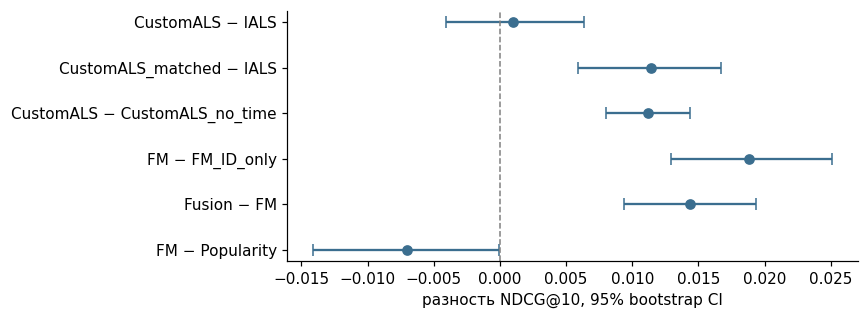

difference  ci_low  ci_high
a                 b                 metric                                
CustomALS         IALS              ndcg@10        0.0010 -0.0041   0.0064
                                    recall@10      0.0030 -0.0054   0.0118
CustomALS_matched IALS              ndcg@10        0.0114  0.0059   0.0167
                                    recall@10      0.0159  0.0070   0.0244
CustomALS         CustomALS_no_time ndcg@10        0.0112  0.0081   0.0143
                                    recall@10      0.0182  0.0124   0.0240
FM                FM_ID_only        ndcg@10        0.0189  0.0129   0.0251
                                    recall@10      0.0296  0.0189   0.0399
Fusion            FM                ndcg@10        0.0144  0.0094   0.0194
                                    recall@10      0.0204  0.0118   0.0289
FM                Popularity        ndcg@10       -0.0070 -0.0141  -0.0000
                                    recall@10     -0.0031 -0.0135   0.0075

In [11]:
ndcg = comparisons[comparisons.metric == "ndcg@10"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 3))
ax.errorbar(ndcg.difference, range(len(ndcg)), xerr=[ndcg.difference - ndcg.ci_low, ndcg.ci_high - ndcg.difference],
            fmt="o", capsize=4, color="#3b6e8f")
ax.axvline(0, color="grey", ls="--", lw=1)
ax.set(yticks=range(len(ndcg)), yticklabels=ndcg.a + " − " + ndcg.b, xlabel="разность NDCG@10, 95% bootstrap CI")
ax.invert_yaxis()
save(fig, "04_test_pairs")
comparisons.set_index(["a", "b", "metric"])

## 7. Выводы

**Какие модели лучше.** На test среди пяти моделей первая FM: NDCG@10 0.0609, Recall@10 0.1014.
Далее идут CustomALS (0.0572) и iALS (0.0563), EASE (0.0530) и ItemKNN (0.0477). Порядок совпадает
с validation, кроме EASE: там он был третьим. Стандартное отклонение по трём seed — 0.0004–0.0019.
При seed 44 FM (0.0572) уступает CustomALS (0.0579), так что порядок этих двух моделей неустойчив.

**Время важнее выбора модели.** Популярность за последние 30 дней (0.0680) точнее любой из пяти
моделей, в том числе FM (разница 0.007, CI [−0.014, 0.000]). Товары моложе 90 дней составляют 2%
каталога, но получают 18% будущих оценок 4–5 (раздел 2). Поэтому модели, которые видят время,
выигрывают у своих вариантов без него.

**Метаданные (FM).** Возраст товара на момент события даёт +0.019 NDCG@10 к FM только с ID,
CI [0.013, 0.025]. Средние по трём seed: 0.0588 против 0.0425. Важно, что признак берётся на дату
события. В v1 признак был постоянным для товара: эмбеддинг товара его поглощал, и FM с признаком
уступала FM только с ID. Набор из трёх признаков на validation хуже одного возраста.

**Собственный сигнал (CustomALS).** Затухание по давности даёт +0.011 к той же модели с $\eta=0$,
CI [0.008, 0.014]. При одинаковых $f$, $\alpha$, $\lambda$ замена цели iALS на цель CustomALS даёт
+0.011, CI [0.006, 0.017] (`CustomALS_matched`). Подобранный на validation CustomALS выиграл у iALS
лишь 0.001, CI [−0.004, 0.006]. Его конфигурация хуже перенеслась на 2014 год: настройки
`CustomALS_matched` на validation давали 0.0443 против 0.0489 у выбранных. Вывод: цель с оценкой
и давностью полезна, но выигрыш над хорошо настроенным iALS зависит от настроек и периода.

**Fusion** 0.7·FM + 0.3·CustomALS даёт лучший результат: 0.0753, +0.014 к FM (CI [0.009, 0.019]).
Популярность Fusion опережает на 0.007, но интервал для этой пары заранее не планировался.

## Источники

- J. McAuley et al. *Image-based recommendations on styles and substitutes*. SIGIR 2015;
  R. He, J. McAuley. *Ups and downs*. WWW 2016 — датасет.
- Y. Hu, Y. Koren, C. Volinsky. *Collaborative filtering for implicit feedback datasets*. ICDM 2008.
- G. Takács, I. Pilászy, D. Tikk. *Applications of the conjugate gradient method for implicit feedback
  collaborative filtering*. RecSys 2011.
- H. Steck. *Embarrassingly shallow autoencoders for sparse data*. WWW 2019.
- S. Rendle. *Factorization machines*. ICDM 2010.